In [9]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

print(tf.__version__)

2.21.0


In [14]:
IMAGE_SIZE = 400
BATCH_SIZE = 32
EPOCHS = 10


In [16]:
train_dir = r"D:\technical\cyint3\stenosis-classification\spinalStenosis\LumbarSpinalStenosis\LumbarSpinalStenosis\train"

dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    shuffle=True,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 10949 files belonging to 3 classes.


In [17]:
class_names = dataset.class_names 
class_names

['Herniated Disc', 'No Stenosis', 'Thecal Sac']

In [18]:
len(dataset)

343

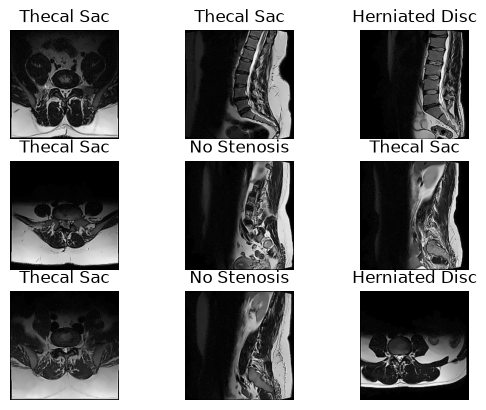

In [31]:
for image_batch, label_batch in dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])
        plt.axis("off")
 


In [32]:
len(dataset)

343

In [36]:
#8% ==> training
#2% ==> 10% validation, 10% test

In [37]:
train_size = int(0.8 * len(dataset))

274

In [38]:
#train_size 274
train_dataset = dataset.take(50)
len(train_dataset)

50

In [39]:
test_dataset = dataset.skip(50)
len(test_dataset)

293

In [40]:
val_size = 0.1
len(test_dataset) * val_size

29.3

In [41]:
test_dataset = dataset.skip(50)
len(test_dataset)

293

In [43]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=10000):
    assert (train_split + val_split + test_split) == 1

    ds_size = len(ds)

    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)

    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)

    train_dataset = ds.take(train_size)
    val_dataset = ds.skip(train_size).take(val_size)
    test_dataset = ds.skip(train_size).skip(val_size)


    return train_dataset, val_dataset, test_dataset


In [44]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)
len(train_ds), len(val_ds), len(test_ds)


(274, 34, 35)

In [45]:
train_ds= train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds= val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds= test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [48]:
resize_and_rescale = tf.keras.Sequential([
    tf.keras.layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    tf.keras.layers.Rescaling(1.0 / 255),
])


In [49]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_vertical", input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
    tf.keras.layers.RandomRotation(0.2),
])

d:\technical\cyint3\.venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
